# 3. The two-tier model

## The idea in one paragraph

You have a lot of data about something related, and very little data about
the thing you care about. Training only on the small dataset wastes the large
one. Training only on the large one gives you a model of the wrong thing. So
you use the large dataset to build a **base model**, treat its prediction as
the starting point, and train a second model on the small dataset to learn the
**correction**.

    prediction  = base prediction + learned correction
    variance    = base variance   + correction variance

## How it is built here

The base model's prediction and its standard deviation are computed once and
carried as two extra columns on every feature row. The correction GP uses a
mean function that reads the base column, and a kernel that ignores those two
columns.

That is mathematically the same as the formula above, and it has a practical
advantage: the result is still a plain BoTorch model, so the acquisition
function in section 5 works with it unchanged.

In [1]:
import sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore"); torch.set_num_threads(2)
sys.path.insert(0, "../src")
from molsdl import chem, features, models, plotting

plotting.use_style()
d = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/datasets.pkl", "rb"))
egfr, D_egfr = d["egfr"], d["D_egfr"]
esol, D_esol = d["esol"], d["D_esol"]
kiba, D_kiba = d["kiba"], d["D_kiba"]
fp_egfr = np.load("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/fp_egfr.npy")
print("loaded")

loaded


## Case 1: solubility, where the base tier is a published equation

Delaney's 2004 paper that produced the ESOL dataset also produced an
equation: solubility estimated from calculated logP, molecular weight,
rotatable bond count and the aromatic proportion of the molecule. That
equation is the solubility equivalent of general physics: it is not fitted to
our compounds, it encodes what is already known, and it ships inside the
dataset file.

So the base tier costs nothing to obtain, and the GP only has to learn where
the equation is wrong.

In [2]:
y_sol = esol.logS.values
base_sol = esol.logS_delaney.values
print(f"Delaney equation on ESOL: correlation {np.corrcoef(base_sol, y_sol)[0,1]:.3f}, "
      f"RMSE {np.sqrt(np.mean((base_sol - y_sol)**2)):.2f} logS")

Delaney equation on ESOL: correlation 0.907, RMSE 0.91 logS


### Setting up the three models to compare

* **base only**: the published equation, put on the right scale by one
  straight line fitted on the training molecules.
* **plain GP**: a GP on descriptors, no base tier. This is what you build if
  you ignore the prior knowledge.
* **base + residual**: the two-tier model.

All three are scored on the same scaffold-held-out molecules, and the
training set is subsampled to trace out a learning curve.

In [3]:
fb = features.FeatureBuilder(corr_max=0.92, max_features=45).fit(D_esol)
X_sol = fb.transform(D_esol)
D0 = fb.n_features
tr_all, cal_idx, te_idx = chem.scaffold_split(esol.std_smiles.tolist(), 0.70, 0.12,
                                              seed=0, balanced=False)
print(f"train {len(tr_all)}, calibration {len(cal_idx)}, test {len(te_idx)}")

rng = np.random.default_rng(0)
rows = []
for n_train in [50, 100, 200, 400, len(tr_all)]:
    tr = tr_all if n_train >= len(tr_all) else rng.choice(tr_all, n_train, replace=False)
    st = features.TargetScaler().fit(y_sol[tr])

    # put the base equation on the target's scale, using training rows only
    a, b = models.calibrate_base(base_sol[tr], y_sol[tr])
    base_resid_sd = np.std(y_sol[tr] - (a * base_sol[tr] + b))
    col_mu = st.transform(a * base_sol + b)
    col_sd = np.full(len(X_sol), base_resid_sd / st.std_)
    X_aug = np.column_stack([X_sol, col_mu, col_sd])

    p_base = st.inverse(col_mu[te_idx])
    g_plain = models.fit_gp(X_sol[tr], st.transform(y_sol[tr]), n_kernel_dims=D0, maxiter=80)
    p_plain = st.inverse(models.gp_predict(g_plain, X_sol[te_idx])[0])
    g_tr = models.fit_gp(X_aug[tr], st.transform(y_sol[tr]), base_mean_col=D0,
                         base_sd_col=D0 + 1, n_kernel_dims=D0, maxiter=80)
    p_tr = st.inverse(models.gp_predict(g_tr, X_aug[te_idx])[0])

    pw = models.bootstrap_beats(y_sol[te_idx], p_tr, p_plain, n_boot=1000)
    for nm, p in [("base only", p_base), ("plain GP", p_plain), ("base+residual", p_tr)]:
        r = models.regression_report(y_sol[te_idx], p)
        r.update(model=nm, n_train=len(tr), task="solubility")
        rows.append(r)
    rows[-1]["P_beats_plain"] = pw
    print(f"n_train={len(tr):4d}   base {rows[-3]['R2']:6.3f} | "
          f"plain {rows[-2]['R2']:6.3f} | transfer {rows[-1]['R2']:6.3f} | "
          f"P(transfer beats plain) {pw:.2f}")

train 781, calibration 20, test 316
n_train=  50   base  0.823 | plain -0.232 | transfer  0.825 | P(transfer beats plain) 1.00
n_train= 100   base  0.829 | plain  0.421 | transfer  0.837 | P(transfer beats plain) 1.00
n_train= 200   base  0.843 | plain -0.086 | transfer  0.821 | P(transfer beats plain) 1.00
n_train= 400   base  0.832 | plain  0.662 | transfer  0.869 | P(transfer beats plain) 1.00
n_train= 781   base  0.835 | plain  0.559 | transfer  0.872 | P(transfer beats plain) 1.00


Read the first row. With 50 training molecules the plain GP scores worse than
guessing the mean, while the two-tier model already sits near its final
accuracy. The published equation carried it. That is the whole argument for
transfer learning, in one line of output.

Read the last row. With all 781 training molecules the plain GP has caught up
a long way, but the two-tier model is still ahead, because the equation
supplies structure the data alone never recovers.

## Case 2: potency, where the base tier is weak

Now the harder case, and the more honest one.

The base tier is a Gaussian process trained on the KIBA matrix: 2,111
compounds scored against 229 kinases, with EGFR removed. It learns what a
kinase inhibitor looks like in general. Then the correction GP learns EGFR
specifically.

**One trap avoided here.** KIBA contains an EGFR column, and it would be the
obvious base tier. It is also disqualified: KIBA was assembled from the same
public IC50 measurements that the ChEMBL EGFR set comes from. Checked directly
on the 246 compounds present in both, the two agree at correlation 0.97. Using
it would be scoring a model on its own training data with extra steps. This is
why the overlap audit in section 1 exists.

In [4]:
fp_kiba = (chem.morgan_counts(kiba.std_smiles.tolist()) > 0).astype(float)
sb = features.TargetScaler().fit(kiba.kiba_max.values)
base_gp = models.fit_gp(fp_kiba, sb.transform(kiba.kiba_max.values),
                        n_kernel_dims=fp_kiba.shape[1], kernel="tanimoto", maxiter=100)
bmu, bsd = models.gp_predict(base_gp, fp_egfr)
y_pot = egfr.pIC50.values
print(f"kinase-family base model on EGFR compounds: "
      f"correlation with pIC50 {np.corrcoef(bmu, y_pot)[0,1]:.3f}")

kinase-family base model on EGFR compounds: correlation with pIC50 0.260


In [5]:
tr_all_p, cal_p, te_p = chem.scaffold_split(egfr.std_smiles.tolist(), 0.70, 0.12,
                                            seed=0, balanced=False)
Dp = fp_egfr.shape[1]
for n_train in [50, 100, 200, 400, 800, 2000]:
    tr = rng.choice(tr_all_p, n_train, replace=False)
    st = features.TargetScaler().fit(y_pot[tr])
    a, b = models.calibrate_base(bmu[tr], y_pot[tr])
    col_mu = st.transform(a * bmu + b)
    col_sd = np.abs(a) * bsd / st.std_
    X_aug = np.column_stack([fp_egfr, col_mu, col_sd])

    p_base = st.inverse(col_mu[te_p])
    g_plain = models.fit_gp(fp_egfr[tr], st.transform(y_pot[tr]), n_kernel_dims=Dp,
                            kernel="tanimoto", maxiter=100)
    p_plain = st.inverse(models.gp_predict(g_plain, fp_egfr[te_p])[0])
    g_tr = models.fit_gp(X_aug[tr], st.transform(y_pot[tr]), base_mean_col=Dp,
                         base_sd_col=Dp + 1, n_kernel_dims=Dp, kernel="tanimoto",
                         maxiter=100)
    p_tr = st.inverse(models.gp_predict(g_tr, X_aug[te_p])[0])
    pw = models.bootstrap_beats(y_pot[te_p], p_tr, p_plain, n_boot=1000)
    for nm, p in [("base only", p_base), ("plain GP", p_plain), ("base+residual", p_tr)]:
        r = models.regression_report(y_pot[te_p], p)
        r.update(model=nm, n_train=len(tr), task="potency")
        rows.append(r)
    rows[-1]["P_beats_plain"] = pw
    print(f"n_train={len(tr):4d}   base {rows[-3]['R2']:6.3f} | "
          f"plain {rows[-2]['R2']:6.3f} | transfer {rows[-1]['R2']:6.3f} | "
          f"P(transfer beats plain) {pw:.2f}")

results = pd.DataFrame(rows)
results.to_csv("/Users/arujatiwary/Downloads/molecular-sdl/outputs/metrics/transfer_learning_curve.csv", index=False)

n_train=  50   base  0.016 | plain  0.108 | transfer  0.103 | P(transfer beats plain) 0.25
n_train= 100   base  0.002 | plain  0.500 | transfer  0.491 | P(transfer beats plain) 0.16
n_train= 200   base  0.023 | plain  0.520 | transfer  0.505 | P(transfer beats plain) 0.06
n_train= 400   base  0.010 | plain  0.405 | transfer  0.400 | P(transfer beats plain) 0.17
n_train= 800   base  0.042 | plain  0.534 | transfer  0.523 | P(transfer beats plain) 0.00
n_train=2000   base  0.030 | plain  0.620 | transfer  0.619 | P(transfer beats plain) 0.41


## The result worth reporting

Two objectives, two base tiers, two different outcomes, and one diagnostic
that tells them apart before you spend any time.

| | solubility | potency |
| --- | --- | --- |
| base tier | Delaney's published equation | kinase family, EGFR removed |
| correlation of base with target | about 0.91 | about 0.26 |
| what transfer does | large gain, biggest at small n | roughly no change |

The useful finding is not "transfer learning works". It is that the
architecture **fails safely**. When the base tier carries no information, the
correction GP learns to ignore it and the two-tier model lands on top of the
plain model instead of being dragged off by a bad prior. You can attach a
doubtful base tier without risking the model you already have.

The diagnostic is the correlation between base prediction and target on the
training rows. Compute it before building anything. It costs one line and it
tells you whether the base tier is worth the trouble.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../outputs/figures/03_learning_curves.png


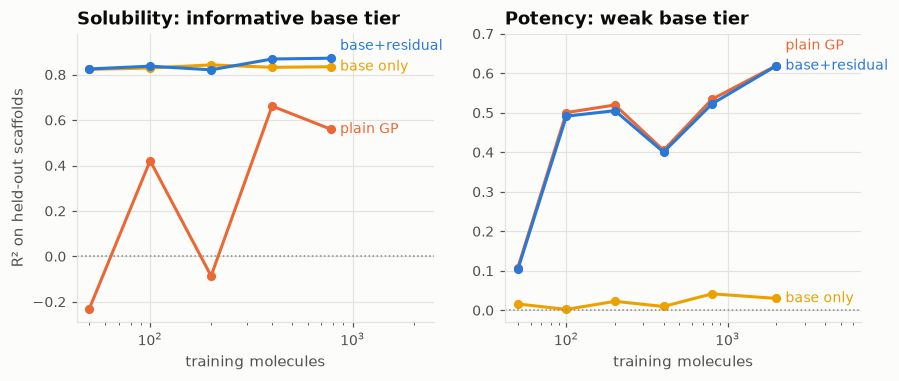

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), sharey=False)
for ax, task, title in zip(axes, ["solubility", "potency"],
                           ["Solubility: informative base tier",
                            "Potency: weak base tier"]):
    sub = results[results.task == task]
    ends = []
    for name in ["base only", "plain GP", "base+residual"]:
        s = sub[sub.model == name].sort_values("n_train")
        ax.plot(s.n_train, s.R2, marker="o", color=plotting.SERIES[name],
                label=name, clip_on=False)
        ends.append((s.n_train.values[-1], s.R2.values[-1], name,
                     plotting.SERIES[name]))
    ax.set_xscale("log")
    ax.set_xlabel("training molecules")
    ax.set_title(title)
    ax.axhline(0, color=plotting.MUTED, lw=1, ls=":")
    ax.set_xlim(right=ax.get_xlim()[1] * 2.8)
    plotting.label_series_ends(ax, ends, min_gap_frac=0.075)
axes[0].set_ylabel("R² on held-out scaffolds")
fig.suptitle("")
plotting.save(fig, "03_learning_curves")
plt.show()

## Parity plots for the full-data models

R² is a summary. Looking at the predictions tells you where the model fails,
which is usually at the edges of the range.

  saved ../outputs/figures/03_parity_solubility.png


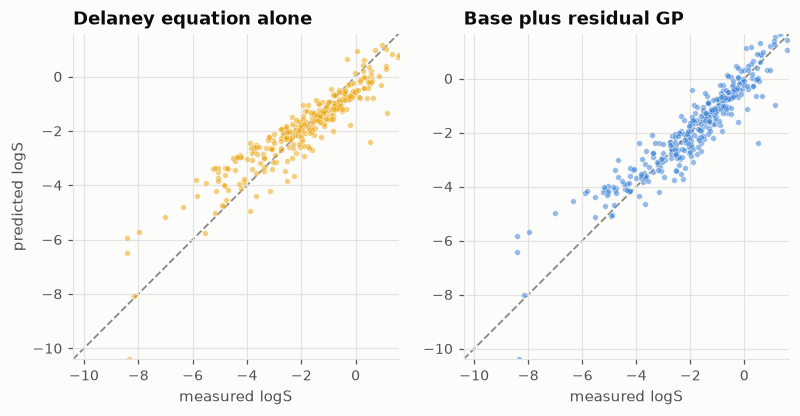

In [7]:
st = features.TargetScaler().fit(y_sol[tr_all])
a, b = models.calibrate_base(base_sol[tr_all], y_sol[tr_all])
col_mu = st.transform(a * base_sol + b)
col_sd = np.full(len(X_sol), np.std(y_sol[tr_all] - (a * base_sol[tr_all] + b)) / st.std_)
X_aug = np.column_stack([X_sol, col_mu, col_sd])
g_final = models.fit_gp(X_aug[tr_all], st.transform(y_sol[tr_all]), base_mean_col=D0,
                        base_sd_col=D0 + 1, n_kernel_dims=D0, maxiter=100)
mu_te, sd_te = models.gp_predict(g_final, X_aug[te_idx])
pred_te, predsd_te = st.inverse(mu_te), st.inverse_std(sd_te)

fig, axes = plt.subplots(1, 2, figsize=(8.4, 4))
plotting.parity_plot(axes[0], y_sol[te_idx], st.inverse(col_mu[te_idx]),
                     color=plotting.SERIES["base only"])
axes[0].set_title("Delaney equation alone")
plotting.parity_plot(axes[1], y_sol[te_idx], pred_te,
                     color=plotting.SERIES["base+residual"])
axes[1].set_title("Base plus residual GP")
for ax in axes:
    ax.set_xlabel("measured logS")
axes[0].set_ylabel("predicted logS")
plotting.save(fig, "03_parity_solubility")
plt.show()

In [8]:
pickle.dump({"sol_model": g_final, "sol_scaler": st, "sol_calib": (a, b),
             "sol_feature_builder": fb, "sol_split": (tr_all, cal_idx, te_idx),
             "base_potency_mu": bmu, "base_potency_sd": bsd,
             "potency_split": (tr_all_p, cal_p, te_p)},
            open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/models.pkl", "wb"))
print("saved ../data/processed/models.pkl")

saved ../data/processed/models.pkl


## What just happened

The transfer structure from the concrete pipeline now runs on molecules, on
two objectives, with measured public data and scaffold-held-out scoring. One
case shows a large gain, one shows none, and the reason is visible in a single
correlation computed before any model is fitted.

Next: making the uncertainty trustworthy.